# Restauración de fotos antiguas con Deep Learning (GAN / U-Net)

Trabajo práctico — Tecnicatura Superior en Ciencia de Datos e IA.

Este notebook entrena una red generativa (arquitectura U-Net como generador + discriminador, estilo Pix2Pix) para restaurar fotografías con daño simulado (grietas, manchas de humedad, viraje sepia/blanco y negro), generando el propio dataset de entrenamiento a partir de imágenes originales.

**Nota:** el notebook fue desarrollado en Google Colab y usa rutas de Google Drive personales (`/content/drive/MyDrive/...`) para el dataset de origen. Para reproducir el entrenamiento completo hay que montar tu propio Drive y actualizar esas rutas. El repositorio incluye el modelo ya entrenado (`modelo_entrenado.keras`) para poder usarlo directamente sin volver a entrenar.

Ver el README.md del repositorio para el resumen ejecutivo del proyecto.

In [ ]:
import os
import cv2
import numpy as np
import glob
import shutil
from google.colab import drive

# 1. Conectar a Google Drive
drive.mount('/content/drive')
# Ajustá esta ruta a la carpeta donde tengas el ZIP del dataset (CelebFaces 64x64, Kaggle)
CARPETA_PROYECTO = "/content/drive/MyDrive/restauracion-fotos/"
ruta_zip = os.path.join(CARPETA_PROYECTO, "celeba_64x64.zip")

# Limpieza de las carpetas viejas para no mezclar los datos
for carpeta in ["/content/dataset_imagenes", "/content/dataset_originales", "/content/dataset_danadas", "/content/dataset_mascaras"]:
    if os.path.exists(carpeta):
        shutil.rmtree(carpeta)

if os.path.exists(ruta_zip):
    print("¡Archivo ZIP encontrado! Descomprimiendo...")
    !unzip -q "{ruta_zip}" -d "/content/dataset_imagenes"
else:
    print("Error crítico: No se encuentra el archivo ZIP.")

# 2. NUEVA FUNCIÓN: Ruleta de colores
def aplicar_filtro_color(imagen):
    eleccion = np.random.choice(['color', 'bn', 'sepia'])

    if eleccion == 'bn':
        # Pasamos a gris y volvemos a BGR para mantener los 3 canales que pide la red
        gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)
        return cv2.cvtColor(gris, cv2.COLOR_GRAY2BGR)

    elif eleccion == 'sepia':
        # Matriz matemática estándar para simular película sepia en formato BGR
        kernel = np.array([[0.272, 0.534, 0.131],
                           [0.349, 0.686, 0.168],
                           [0.393, 0.769, 0.189]])
        sepia = cv2.transform(imagen, kernel)
        return np.clip(sepia, 0, 255).astype(np.uint8)

    return imagen # Si sale 'color', la devuelve intacta

# 3. FUNCIÓN DE DAÑO (Grietas y Manchas)
def aplicar_danio_fotos_viejas(imagen):
    img_danada = imagen.copy()
    h, w, _ = imagen.shape

    # Grietas
    for _ in range(np.random.randint(3, 8)):
        x, y = np.random.randint(0, w), np.random.randint(0, h)
        for _ in range(np.random.randint(4, 10)):
            nx = np.clip(x + np.random.randint(-15, 15), 0, w-1)
            ny = np.clip(y + np.random.randint(-15, 15), 0, h-1)
            # El color de la grieta ahora es ligeramente amarillento/sucio
            cv2.line(img_danada, (x, y), (nx, ny), (220, 230, 240), 1)
            x, y = nx, ny

    # Manchas de humedad
    for _ in range(np.random.randint(1, 4)):
        cx, cy = np.random.randint(0, w), np.random.randint(0, h)
        radio = np.random.randint(2, 8)
        cv2.circle(img_danada, (cx, cy), radio, (200, 200, 200), -1)

    return img_danada

# --- 4. PIPELINE CON DIVISIÓN 80/20 ---
def preparar_pipeline_con_split(ruta_origen):
    # Obtener lista de todos los archivos
    imagenes_path = glob.glob(os.path.join(ruta_origen, "**", "*.jpg"), recursive=True)
    n_total = len(imagenes_path)
    n_train = int(n_total * 0.8)

    # Mezclamos los datos para que el split sea aleatorio
    np.random.shuffle(imagenes_path)

    train_paths = imagenes_path[:n_train]
    test_paths = imagenes_path[n_train:]

    print(f"Total: {n_total} | Train: {len(train_paths)} | Test: {len(test_paths)}")

    # Creamos las carpetas de salida
    os.makedirs("/content/dataset_danadas/train", exist_ok=True)
    os.makedirs("/content/dataset_originales/train", exist_ok=True)
    os.makedirs("/content/dataset_danadas/test", exist_ok=True)
    os.makedirs("/content/dataset_originales/test", exist_ok=True)

    # Función para procesar y guardar
    def procesar_y_guardar(lista_paths, sub_carpeta):
        for path in lista_paths:
            nombre = os.path.basename(path)
            img = cv2.imread(path)
            if img is None: continue

            img_hist = aplicar_filtro_color(img)
            img_danada = aplicar_danio_fotos_viejas(img_hist)

            cv2.imwrite(f"/content/dataset_originales/{sub_carpeta}/{nombre}", img_hist)
            cv2.imwrite(f"/content/dataset_danadas/{sub_carpeta}/{nombre}", img_danada)

    print("Generando partición de entrenamiento...")
    procesar_y_guardar(train_paths, "train")
    print("Generando partición de validación...")
    procesar_y_guardar(test_paths, "test")

# --- 5. EJECUCIÓN ---
if os.path.exists(ruta_zip):
    preparar_pipeline_con_split("/content/dataset_imagenes")
    print("¡Dataset dividido en Train (80%) y Test (20%) con éxito!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
¡Archivo ZIP encontrado! Descomprimiendo...
Total: 50000 | Train: 40000 | Test: 10000
Generando partición de entrenamiento...
Generando partición de validación...
¡Dataset dividido en Train (80%) y Test (20%) con éxito!


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

# --- 1. GENERADOR (U-Net) ---
def construir_generador():
    entradas = layers.Input(shape=[64, 64, 3])

    # Encoder
    e1 = layers.Conv2D(64, kernel_size=4, strides=2, padding='same')(entradas)
    e1 = layers.LeakyReLU(alpha=0.2)(e1)

    e2 = layers.Conv2D(128, kernel_size=4, strides=2, padding='same')(e1)
    e2 = layers.BatchNormalization()(e2)
    e2 = layers.LeakyReLU(alpha=0.2)(e2)

    e3 = layers.Conv2D(256, kernel_size=4, strides=2, padding='same')(e2)
    e3 = layers.BatchNormalization()(e3)
    e3 = layers.LeakyReLU(alpha=0.2)(e3)

    # Decoder
    d1 = layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding='same')(e3)
    d1 = layers.BatchNormalization()(d1)
    d1 = layers.ReLU()(d1)
    d1_concat = layers.Concatenate()([d1, e2])

    d2 = layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding='same')(d1_concat)
    d2 = layers.BatchNormalization()(d2)
    d2 = layers.ReLU()(d2)
    d2_concat = layers.Concatenate()([d2, e1])

    salida = layers.Conv2DTranspose(3, kernel_size=4, strides=2, padding='same', activation='tanh')(d2_concat)
    return Model(inputs=entradas, outputs=salida, name="Generador_UNet")

# --- 2. DISCRIMINADOR ---
def construir_discriminador():
    entradas = layers.Input(shape=[64, 64, 3])

    x = layers.Conv2D(64, kernel_size=4, strides=2, padding='same')(entradas)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(128, kernel_size=4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(256, kernel_size=4, strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Flatten()(x)
    salida = layers.Dense(1)(x)
    return Model(inputs=entradas, outputs=salida, name="Discriminador")

generador = construir_generador()
discriminador = construir_discriminador()
print("¡Arquitecturas compiladas correctamente!")

¡Arquitecturas compiladas correctamente!


/usr/local/lib/python3.12/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


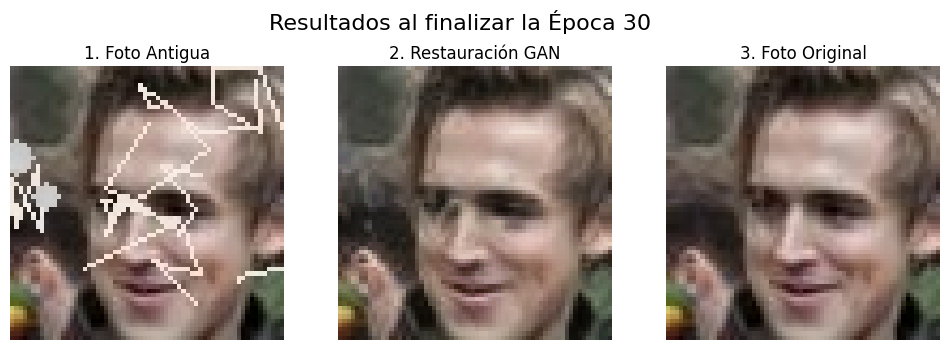

Época 30 completada en 49 seg.
Loss Generador: 8.5094 | Loss Discriminador: 0.2811


In [ ]:
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output
import tensorflow as tf

# --- 1. PIPELINE DE DATOS ---
BATCH_SIZE = 32

def cargar_y_procesar_imagen(ruta_danada):
    ruta_original = tf.strings.regex_replace(ruta_danada, "dataset_danadas", "dataset_originales")

    img_danada = tf.io.read_file(ruta_danada)
    img_danada = tf.image.decode_jpeg(img_danada, channels=3)
    img_danada = (tf.cast(img_danada, tf.float32) / 127.5) - 1.0

    img_original = tf.io.read_file(ruta_original)
    img_original = tf.image.decode_jpeg(img_original, channels=3)
    img_original = (tf.cast(img_original, tf.float32) / 127.5) - 1.0

    return img_danada, img_original

# En el Bloque 3, cambiá esta línea:
rutas_danadas = tf.data.Dataset.list_files("/content/dataset_danadas/train/*.jpg", shuffle=True)
dataset = rutas_danadas.map(cargar_y_procesar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# --- 2. OPTIMIZADORES Y FUNCIONES DE PÉRDIDA ESTABLES ---
opt_generador = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
opt_discriminador = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def loss_discriminador(disc_real, disc_generado):
    loss_real = loss_object(tf.ones_like(disc_real), disc_real)
    loss_falso = loss_object(tf.zeros_like(disc_generado), disc_generado)
    return loss_real + loss_falso

def loss_generador(disc_generado, imagen_generada, imagen_original):
    # Volvemos a la configuración clásica de Pix2Pix que no explota
    loss_adv = loss_object(tf.ones_like(disc_generado), disc_generado)
    loss_l1 = tf.reduce_mean(tf.abs(imagen_original - imagen_generada))
    return loss_adv + (100 * loss_l1)

@tf.function
def paso_entrenamiento(imagen_danada, imagen_original):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        imagen_generada = generador(imagen_danada, training=True)
        disc_real = discriminador(imagen_original, training=True)
        disc_falso = discriminador(imagen_generada, training=True)

        gen_loss = loss_generador(disc_falso, imagen_generada, imagen_original)
        disc_loss = loss_discriminador(disc_real, disc_falso)

    gradientes_generador = gen_tape.gradient(gen_loss, generador.trainable_variables)
    gradientes_discriminador = disc_tape.gradient(disc_loss, discriminador.trainable_variables)

    opt_generador.apply_gradients(zip(gradientes_generador, generador.trainable_variables))
    opt_discriminador.apply_gradients(zip(gradientes_discriminador, discriminador.trainable_variables))
    return gen_loss, disc_loss

# --- 3. VISUALIZACIÓN Y BUCLE PRINCIPAL ---
def generar_y_mostrar_imagenes(modelo, entrada_prueba, objetivo_prueba, epoca):
    prediccion = modelo(entrada_prueba, training=False)
    plt.figure(figsize=(12, 4))
    lista_imagenes = [entrada_prueba[0], prediccion[0], objetivo_prueba[0]]
    titulos = ['1. Foto Antigua', '2. Restauración GAN', '3. Foto Original']

    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(titulos[i])
        plt.imshow(lista_imagenes[i] * 0.5 + 0.5)
        plt.axis('off')

    plt.suptitle(f"Resultados al finalizar la Época {epoca}", fontsize=16)
    plt.show()

def entrenar_con_graficos(dataset, epocas):
    print("¡Reiniciando el entrenamiento de forma estable!")
    for lote_danado, lote_original in dataset.take(1):
        entrada_prueba = lote_danado
        objetivo_prueba = lote_original

    for epoca in range(epocas):
        inicio = time.time()
        gen_loss_total = 0
        disc_loss_total = 0
        lotes = 0

        for lote_danado, lote_original in dataset:
            g_loss, d_loss = paso_entrenamiento(lote_danado, lote_original)
            gen_loss_total += g_loss
            disc_loss_total += d_loss
            lotes += 1

        clear_output(wait=True)
        generar_y_mostrar_imagenes(generador, entrada_prueba, objetivo_prueba, epoca + 1)

        tiempo_epoca = time.time() - inicio
        print(f"Época {epoca + 1} completada en {tiempo_epoca:.0f} seg.")
        print(f"Loss Generador: {gen_loss_total/lotes:.4f} | Loss Discriminador: {disc_loss_total/lotes:.4f}")

# --- 4. ARRANQUE SEGURO ---
entrenar_con_graficos(dataset, epocas=30)

In [ ]:
# --- GUARDAR MODELO EN LA CARPETA DEL DATASET ---
# Se guarda en la misma carpeta del proyecto definida al inicio
ruta_carpeta_dataset = CARPETA_PROYECTO
nombre_archivo = "modelo_entrenado.keras"

# Construimos la ruta completa
ruta_guardado = os.path.join(ruta_carpeta_dataset, nombre_archivo)

# Guardamos el modelo
generador.save(ruta_guardado)

print(f"¡Modelo guardado exitosamente en:")
print(f"{ruta_guardado}")

¡Modelo guardado exitosamente en:
/content/drive/MyDrive/restauracion-fotos/modelo_entrenado.keras


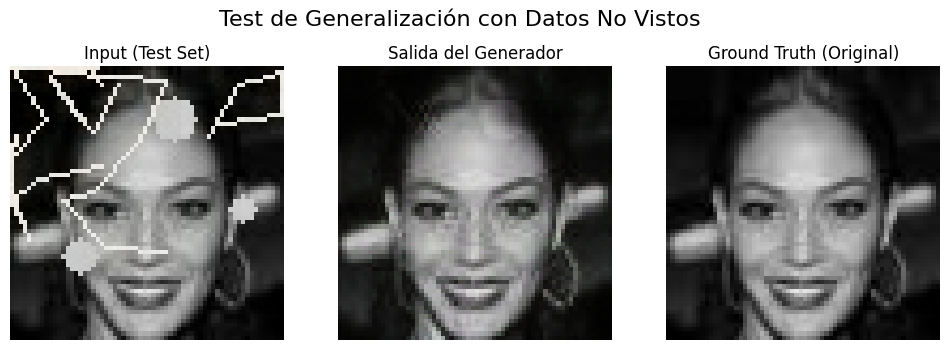

In [ ]:
import random

# --- TEST DE GENERALIZACIÓN (Validación Externa) ---
def realizar_test_generalizacion():
    # Buscamos una imagen en la carpeta test
    test_paths = glob.glob("/content/dataset_danadas/test/*.jpg")
    if not test_paths:
        print("No se encontraron imágenes en la carpeta de test.")
        return

    # Elegimos una al azar
    ruta_aleatoria = random.choice(test_paths)

    # Cargamos y procesamos
    img_danada, img_original = cargar_y_procesar_imagen(ruta_aleatoria)
    img_danada = np.expand_dims(img_danada, axis=0) # Batch de 1

    # Inferencia
    restauracion = generador(img_danada, training=False)

    # Visualización
    plt.figure(figsize=(12, 4))
    lista = [img_danada[0], restauracion[0], img_original]
    titulos = ['Input (Test Set)', 'Salida del Generador', 'Ground Truth (Original)']

    for i in range(3):
        plt.subplot(1, 3, i+1)
        plt.title(titulos[i])
        plt.imshow(lista[i] * 0.5 + 0.5)
        plt.axis('off')

    plt.suptitle("Test de Generalización con Datos No Vistos", fontsize=16)
    plt.show()

# ¡Ejecutalo!
realizar_test_generalizacion()